### Data Details ###

    - Main Dataset stored on: SUIT_Payload_Part1 (17 FITS files)
    - Data Pre-processing and Detection of Active Regions performed
    - Attributes of Centroids and Mean Area extracted (using region_props())
    - Validation performed against NOAA datasets via HEK (Heliophysics Events Knowledgebase)

In [8]:
import glob

SUIT_FITS_Files = sorted(glob.glob('SUIT_Payload_Part1/*.fits'))
print("Number of FITS Files from the SUIT Catalogue:", len(SUIT_FITS_Files))

Number of FITS Files from the SUIT Catalogue: 17


In [9]:
from astropy.io import fits

for file in SUIT_FITS_Files:
    hdul = fits.open(file)
    header = hdul[0].header
    print(header)
    hdul.close()

SIMPLE  =                    T / conforms to FITS standard                      BITPIX  =                   32 / array data type                                NAXIS   =                    2 / number of array dimensions                     NAXIS1  =                  560 / lines in image                                 NAXIS2  =                  560 / pixels in a line                               EXTEND  =                    T                                                  GRT_DT  = '2026-05-15T07:13:14.918' / GRT Time                                  DHOBT_DT= '2026-05-14T23:04:35.822655000' / UTC time with respect to DHOBT      FRM_CNT =                 3801 / Frame counter                                  DHOBTCNT=         109904749378 / DHOBT Counter Clock                            SDRAM   =           1487142912 / SDRAM Headers                                  PACKET  =           4188285873 / Header identifier                              IMGTRID =                22691 / Image T

                                                 file         day  \
0   SUIT_Payload_Part1\SUT_T26_0649_002132_Lev1.0_...  2026-05-09   
1   SUIT_Payload_Part1\SUT_T26_0649_002132_Lev1.0_...  2026-05-09   
2   SUIT_Payload_Part1\SUT_T26_0649_002132_Lev1.0_...  2026-05-09   
3   SUIT_Payload_Part1\SUT_T26_0651_002137_Lev1.0_...  2026-05-10   
4   SUIT_Payload_Part1\SUT_T26_0651_002137_Lev1.0_...  2026-05-10   
5   SUIT_Payload_Part1\SUT_T26_0637_002138_Lev1.0_...  2026-05-11   
6   SUIT_Payload_Part1\SUT_T26_0637_002138_Lev1.0_...  2026-05-11   
7   SUIT_Payload_Part1\SUT_T26_0653_002147_Lev1.0_...  2026-05-12   
8   SUIT_Payload_Part1\SUT_T26_0653_002147_Lev1.0_...  2026-05-12   
9   SUIT_Payload_Part1\SUT_A01_0029_002152_Lev1.0_...  2026-05-13   
10  SUIT_Payload_Part1\SUT_A01_0029_002152_Lev1.0_...  2026-05-13   
11  SUIT_Payload_Part1\SUT_T26_0654_002157_Lev1.0_...  2026-05-14   
12  SUIT_Payload_Part1\SUT_A01_0025_002158_Lev1.0_...  2026-05-14   
13  SUIT_Payload_Part1\SUT_T26_071

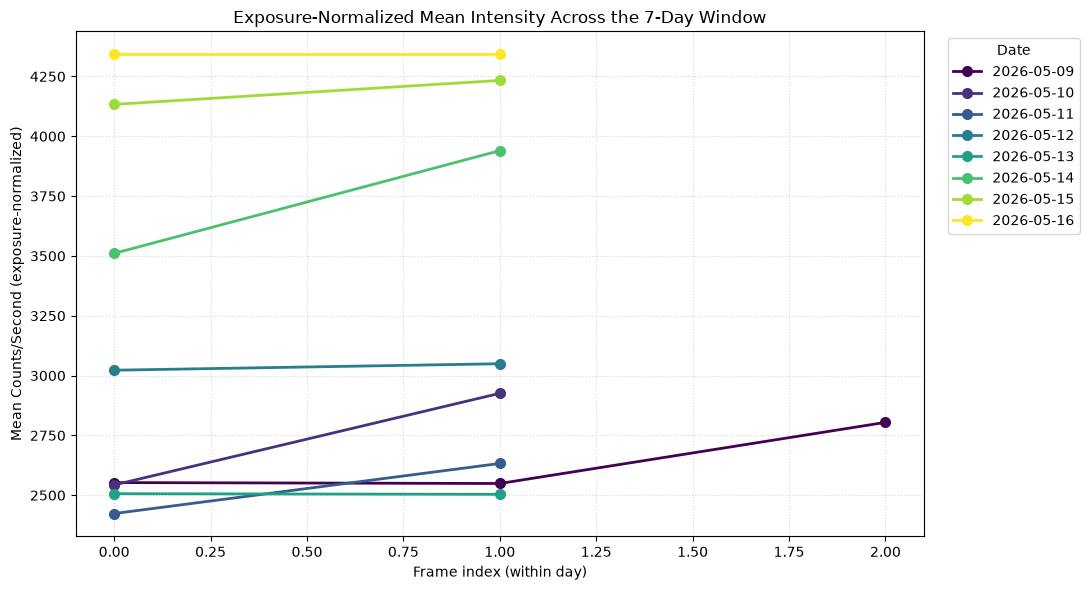

In [10]:
#Stage 01 Normalization: Exposure Normalization --> Ensuring that the exposure levels are the same for all FITS images.
from matplotlib import pyplot as plt
import numpy as np

def exposure_normalization(filepath):
    header = fits.getheader(filepath)
    data = fits.getdata(filepath).astype(float)
    return data / header['EXPTIME'], header

# Stage 01 Normalization: Exposure Normalization — quantitative summary across the 7-day window
import pandas as pd

exposure_stats = []
for file in SUIT_FITS_Files:
    normalized_data, header = exposure_normalization(filepath=file)
    exposure_stats.append({
        'file': file,
        'T_OBS': header['T_OBS'],
        'day': header['T_OBS'][:10],
        'mean_cps': np.mean(normalized_data),
        'median_cps': np.median(normalized_data),
        'p99_cps': np.percentile(normalized_data, 99)
    })

df_exposure = pd.DataFrame(exposure_stats).sort_values('T_OBS').reset_index(drop=True)
print(df_exposure[['file', 'day', 'mean_cps', 'median_cps', 'p99_cps']])

days = sorted(df_exposure['day'].unique())
day_x = {d: i for i, d in enumerate(days)}
x = np.arange(len(days))
cmap = plt.cm.plasma(np.linspace(0.1, 0.85, len(days)))

daily_mean = df_exposure.groupby('day')['mean_cps'].mean().reindex(days)
daily_std  = df_exposure.groupby('day')['mean_cps'].std().reindex(days).fillna(0)

# Plot: normalized brightness trend across the week
fig, ax = plt.subplots(figsize=(11, 6))
days = sorted(df_exposure['day'].unique())
colors = plt.cm.viridis(np.linspace(0, 1, len(days)))

for day, color in zip(days, colors):
    day_df = df_exposure[df_exposure['day'] == day]
    ax.plot(range(len(day_df)), day_df['mean_cps'], 'o-', color=color, label=day, linewidth=2, markersize=7)

ax.set_xlabel('Frame index (within day)')
ax.set_ylabel('Mean Counts/Second (exposure-normalized)')
ax.set_title('Exposure-Normalized Mean Intensity Across the 7-Day Window')
ax.legend(title='Date', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


In [11]:
from collections import defaultdict

files_array = sorted(glob.glob('SUIT_Payload_Part1/*.fits'))

files_roi = []
for file in files_array:
    header = fits.getheader(file)
    if header['FTR_NAME'] == "NB03" and header['ROI_FF'] == "ROI":
        files_roi.append(file)

files_roi.sort(key=lambda file: fits.getheader(file)['T_OBS'])
print(f"Number of files in files_roi: {len(files_roi)}")

files_by_day = defaultdict(list)
for file in files_roi:
    obs_date = fits.getheader(file)['T_OBS'][:10]
    files_by_day[obs_date].append(file)

for day, flist in sorted(files_by_day.items()):
    print(day, "->", len(flist), "files")

Number of files in files_roi: 11
2026-05-09 -> 1 files
2026-05-10 -> 1 files
2026-05-11 -> 1 files
2026-05-12 -> 2 files
2026-05-14 -> 2 files
2026-05-15 -> 2 files
2026-05-16 -> 2 files


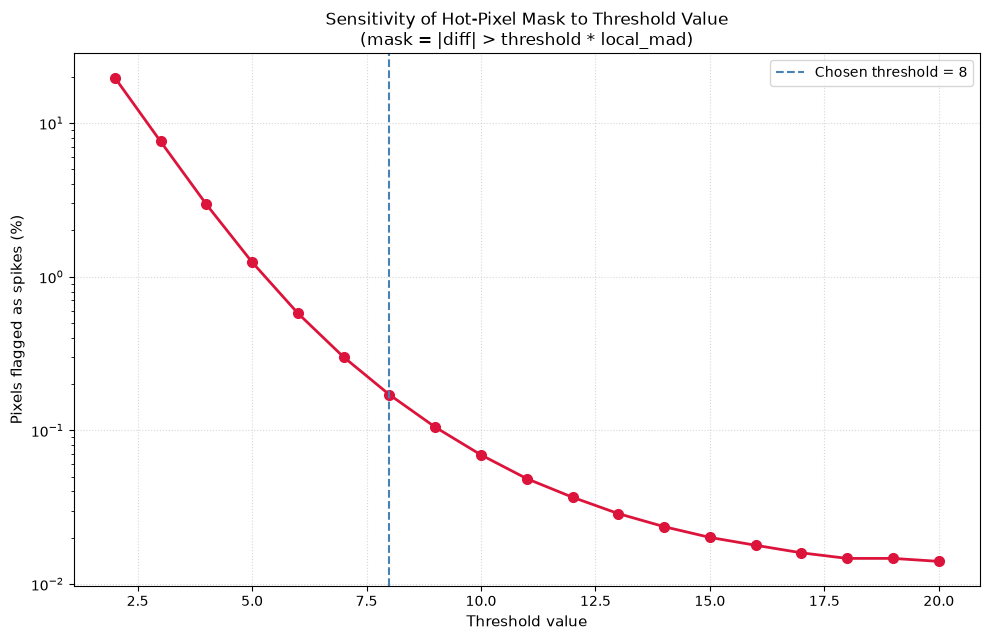

In [12]:
#Stage 02 Normalization: Pixel Correction through Hot-Pixel Removal
from scipy.ndimage import median_filter

def hot_pixel_removal(filepath, size=5, threshold=8):
    normalized_data, header = exposure_normalization(filepath)
    med = median_filter(normalized_data, size=size)             # Replacing each pixel of the image by the median value of the surrounding pixel --> smoothening
    diff = normalized_data - med
    local_mad = median_filter(np.abs(diff), size=size)          # Sliding a 5x5 kernel across each region of the image --> replacing the region with the median value intensity 
        
    mask = np.abs(diff) > (threshold * local_mad)               # Boolean operation --> checking with respect to the Threshold
    cleaned_data = normalized_data.copy()                       # Creating an additional clone of normalized_data
    
    rows, cols = normalized_data.shape
    for row in range(rows):
        for col in range(cols):
            if mask[row, col] == True:
                cleaned_data[row, col] = med[row, col]
    
    n_spikes = mask.sum()                                       # Number of pixels that have been flagged true by the algorithm
    
    return cleaned_data, n_spikes, header, mask


filepath = files_roi[2]   

threshold_values = np.arange(2, 21, 1)
spike_percentages = []

for t in threshold_values:
    cleaned_data, n_spikes, header, mask = hot_pixel_removal(filepath, size=5, threshold=t)
    spike_pct = 100 * n_spikes / mask.size
    spike_percentages.append(spike_pct)

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.plot(threshold_values, spike_percentages, 'o-', color='crimson', linewidth=2, markersize=7)
ax.axvline(8, color='steelblue', linestyle='--', linewidth=1.5, label='Chosen threshold = 8')
ax.set_xlabel('Threshold value', fontsize=11)
ax.set_ylabel('Pixels flagged as spikes (%)', fontsize=11)
ax.set_title('Sensitivity of Hot-Pixel Mask to Threshold Value\n(mask = |diff| > threshold * local_mad)', fontsize=12)
ax.set_yscale('log')
ax.legend()
ax.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

                                                 file         day   mgn_std  \
0   SUIT_Payload_Part1\SUT_T26_0649_002132_Lev1.0_...  2026-05-09  0.251980   
1   SUIT_Payload_Part1\SUT_T26_0649_002132_Lev1.0_...  2026-05-09  0.247729   
2   SUIT_Payload_Part1\SUT_T26_0649_002132_Lev1.0_...  2026-05-09  0.173749   
3   SUIT_Payload_Part1\SUT_T26_0651_002137_Lev1.0_...  2026-05-10  0.245919   
4   SUIT_Payload_Part1\SUT_T26_0651_002137_Lev1.0_...  2026-05-10  0.172425   
5   SUIT_Payload_Part1\SUT_T26_0637_002138_Lev1.0_...  2026-05-11  0.244467   
6   SUIT_Payload_Part1\SUT_T26_0637_002138_Lev1.0_...  2026-05-11  0.160821   
7   SUIT_Payload_Part1\SUT_T26_0653_002147_Lev1.0_...  2026-05-12  0.181264   
8   SUIT_Payload_Part1\SUT_T26_0653_002147_Lev1.0_...  2026-05-12  0.178304   
9   SUIT_Payload_Part1\SUT_A01_0029_002152_Lev1.0_...  2026-05-13  0.242438   
10  SUIT_Payload_Part1\SUT_A01_0029_002152_Lev1.0_...  2026-05-13  0.243822   
11  SUIT_Payload_Part1\SUT_T26_0654_002157_Lev1.0_..

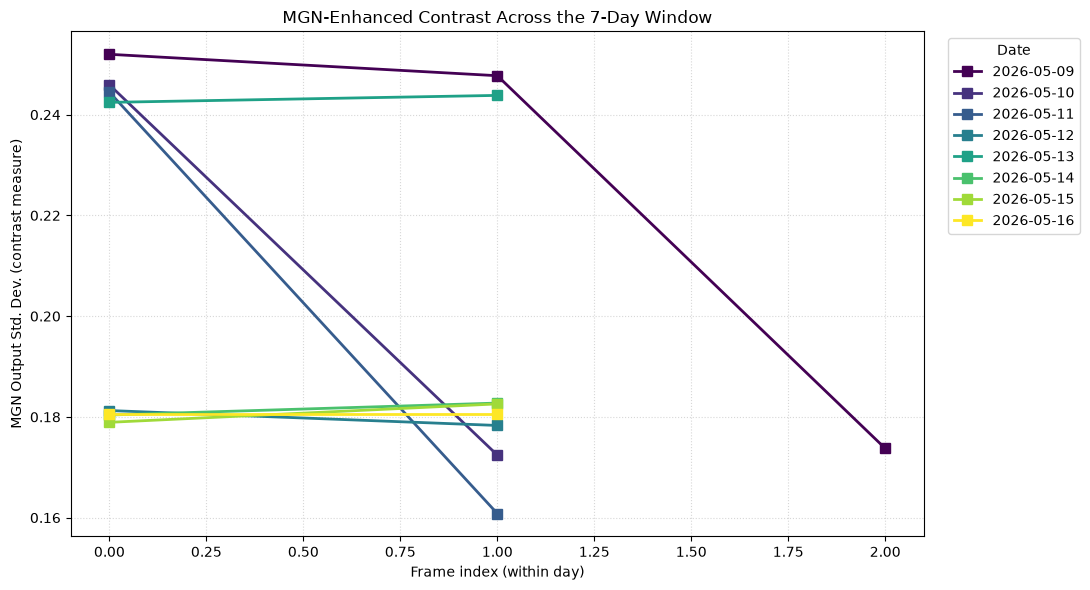

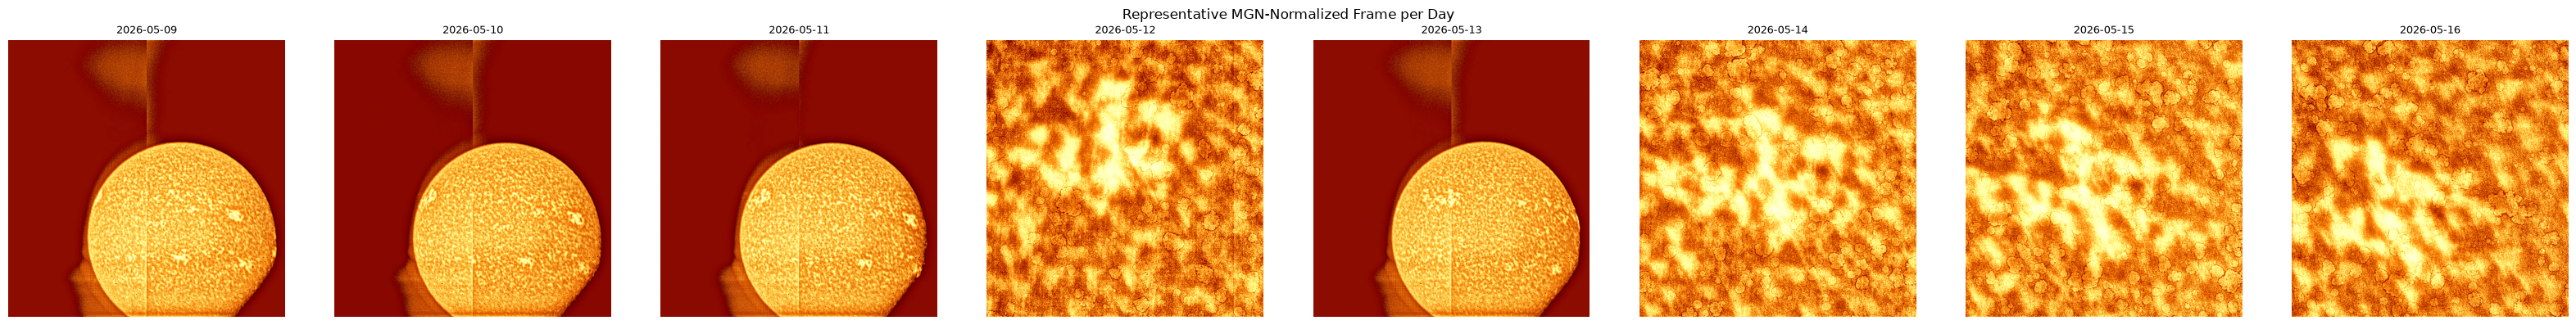

In [13]:
import sunkit_image.enhance as enh

def MGN_Normalization(filepath):
    cleaned_data, n_spikes, header, _ = hot_pixel_removal(filepath)
    mgn_data = enh.mgn(cleaned_data, sigma=None)        # Using the Default array for Sigma
    return mgn_data, n_spikes, header

# Normalization: MGN — Performing a quantitative contrast summary across the 7-day window
mgn_stats = []
for file in SUIT_FITS_Files:
    mgn_data, n_spikes, header = MGN_Normalization(filepath=file)
    mgn_stats.append({
        'file': file,
        'T_OBS': header['T_OBS'],
        'day': header['T_OBS'][:10],
        'mgn_std': np.std(mgn_data),            # contrast/dynamic range after MGN
        'mgn_p99_p1_range': np.percentile(mgn_data, 99) - np.percentile(mgn_data, 1),
        'n_spikes': n_spikes
    })

df_mgn = pd.DataFrame(mgn_stats).sort_values('T_OBS').reset_index(drop=True)
print(df_mgn[['file', 'day', 'mgn_std', 'mgn_p99_p1_range', 'n_spikes']])

# Plot: contrast enhancement trend across the week
fig, ax = plt.subplots(figsize=(11, 6))
for day, color in zip(days, colors):
    day_df = df_mgn[df_mgn['day'] == day]
    ax.plot(range(len(day_df)), day_df['mgn_std'], 's-', color=color, label=day, linewidth=2, markersize=7)

ax.set_xlabel('Frame index (within day)')
ax.set_ylabel('MGN Output Std. Dev. (contrast measure)')
ax.set_title('MGN-Enhanced Contrast Across the 7-Day Window')
ax.legend(title='Date', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

# Daily MGN thumbnail montage (consisting of 7 images)
fig, axes = plt.subplots(1, len(days), figsize=(4*len(days), 4))
for ax_i, day in zip(axes, days):
    rep_file = df_mgn[df_mgn['day'] == day].iloc[0]['file']
    rep_mgn, _, _ = MGN_Normalization(rep_file)
    ax_i.imshow(rep_mgn, cmap='afmhot', origin='lower')
    ax_i.set_title(day, fontsize=9)
    ax_i.axis('off')
plt.suptitle('Representative MGN-Normalized Frame per Day')
plt.tight_layout()
plt.show()





In [14]:
from skimage.registration import phase_cross_correlation
from scipy.ndimage import shift

# Aligning the frames to remove spacecraft jitter

def jitter_alignment(filepaths, upsample_factor = 20):      # upsample_factor --> determines precision (chosen as 20)
    array_of_cleaned_frames = []
    array_headers = []
    for file in filepaths:
        cleaned_data, n_spikes, header, _ = hot_pixel_removal(file)
        array_of_cleaned_frames.append(cleaned_data)
        array_headers.append(fits.getheader(file))

    reference = array_of_cleaned_frames[0]             # Choosing the first frame as the anchor/reference point
    aligned_frames = [reference]
    aligned_headers = [array_headers[0].copy()]   # Creating another copy of array_headers
    measured_shifts = [(0.0, 0.0)]                # Array to store the calculated shift (Anchor frame is not shifted, hence (0.0, 0.0))

    for index in range(1, len(array_of_cleaned_frames)):    # Skipping the first frame, and starting from the second
        shift_vec, _, _ = phase_cross_correlation(reference, array_of_cleaned_frames[index], upsample_factor=upsample_factor)
        aligned_f = shift(array_of_cleaned_frames[index], shift_vec)
        aligned_frames.append(aligned_f)

        h = array_headers[index].copy()

        #Performing the shift in the headers concerning the Centre of the Sun (CRPIX1 and CRPIX2)
        h["CRPIX1"] += shift_vec[1]
        h["CRPIX2"] += shift_vec[0]
        aligned_headers.append(h)
        measured_shifts.append(tuple(shift_vec))

    return aligned_frames, aligned_headers, measured_shifts, array_of_cleaned_frames

daily_results = {}
for day, flist in sorted(files_by_day.items()):
    if len(flist) < 2:
        print(f"Skipping {day}: only {len(flist)} frame(s), nothing to align")
        continue
    aligned_frames, aligned_headers, measured_shifts, cleaned_frames = jitter_alignment(flist)
    daily_results[day] = {
        'aligned_frames': aligned_frames,
        'aligned_headers': aligned_headers,
        'measured_shifts': measured_shifts,
        'cleaned_frames': cleaned_frames
    }
    print(f"{day}: aligned {len(flist)} frames, shifts = {measured_shifts}")

Skipping 2026-05-09: only 1 frame(s), nothing to align
Skipping 2026-05-10: only 1 frame(s), nothing to align
Skipping 2026-05-11: only 1 frame(s), nothing to align
2026-05-12: aligned 2 frames, shifts = [(0.0, 0.0), (np.float64(4.0), np.float64(88.0))]
2026-05-14: aligned 2 frames, shifts = [(0.0, 0.0), (np.float64(0.0), np.float64(147.0))]
2026-05-15: aligned 2 frames, shifts = [(0.0, 0.0), (np.float64(0.0), np.float64(139.0))]
2026-05-16: aligned 2 frames, shifts = [(0.0, 0.0), (np.float64(0.0), np.float64(0.0))]


In [15]:
#Visual interpretation of the results --> contrast between cleaned v/s aligned frames
from matplotlib import pyplot as plt

import matplotlib.pyplot as plt

def plot_line_profile_comparison(cleaned_frames, aligned_frames, row=350, save_path=None):
    fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

    axes[0].plot(cleaned_frames[0][row, :], label='Reference (frame 0)', color='black', linewidth=1.5)
    axes[0].plot(cleaned_frames[-1][row, :], label='Last frame -- BEFORE alignment', color='crimson', linewidth=1.2, linestyle='--')
    axes[0].set_title(f'Intensity profile along row {row} -- BEFORE alignment')
    axes[0].set_ylabel('Counts/second')
    axes[0].legend()

    axes[1].plot(aligned_frames[0][row, :], label='Reference (frame 0)', color='black', linewidth=1.5)
    axes[1].plot(aligned_frames[-1][row, :], label='Last frame -- AFTER alignment', color='seagreen', linewidth=1.2, linestyle='--')
    axes[1].set_title(f'Intensity profile along row {row} -- AFTER alignment')
    axes[1].set_xlabel('Pixel X position')
    axes[1].set_ylabel('Counts/second')
    axes[1].legend()

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=110)
    plt.show()




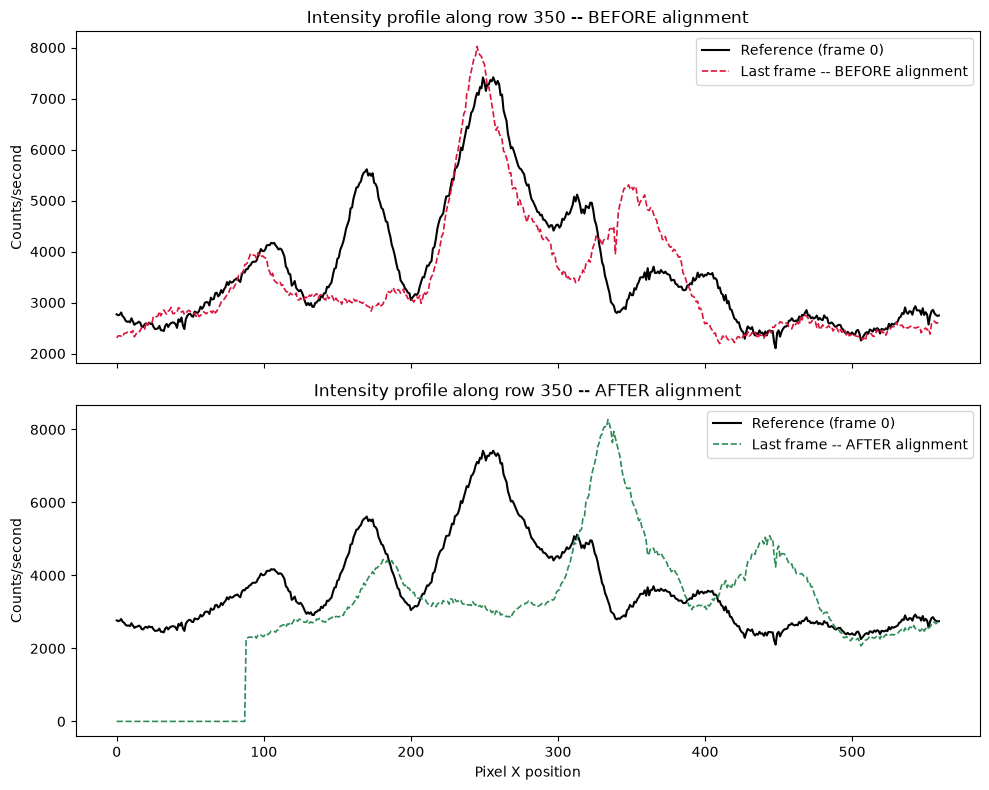

In [16]:
day_to_check = sorted(daily_results.keys())[0]
plot_line_profile_comparison(
    daily_results[day_to_check]['cleaned_frames'],
    daily_results[day_to_check]['aligned_frames'],
    row=350
)

In [17]:
#Threshold Segmentation to isolate bright regions --> Using Otsu's Method

import skimage.filters as f
from skimage import morphology, measure

def thresh_segmentation_and_morphology(data, min_region_size = 20):
    otsu_thresh_val = f.threshold_otsu(data)        # Threshold is chosen implicitly
    binary_mask = data > otsu_thresh_val

    refined_mask = morphology.opening(binary_mask, morphology.disk(2))      #morphology.disk(2) --> Builds a 5x5 gird of True/False values, arranged in a circle of radius = 2
    refined_mask = morphology.closing(refined_mask, morphology.disk(2))
    refined_mask = morphology.remove_small_objects(refined_mask, min_size = min_region_size)

    labeled_regions = measure.label(refined_mask)       # Alotting each region a unique ID number --> primary key
    region_property = measure.regionprops(labeled_regions, intensity_image=data)        # Measuring the Area, Centroid, Brightness for each region considered

    return binary_mask, refined_mask, labeled_regions, region_property, otsu_thresh_val

daily_region_summary = {}
for day, result in sorted(daily_results.items()):
    rep_frame = result['aligned_frames'][0]
    binary_mask, cleaned_mask, labeled_regions, region_props, otsu_thresh_val = thresh_segmentation_and_morphology(rep_frame)
    daily_region_summary[day] = region_props
    print(f"{day}: threshold={otsu_thresh_val:.2f}, regions found={len(region_props)}")
    for r in region_props:
        print(f"   Region {r.label}: area={r.area}, centroid={r.centroid}")

C:\Users\kriti\AppData\Local\Temp\ipykernel_17312\3970980654.py:12: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  refined_mask = morphology.remove_small_objects(refined_mask, min_size = min_region_size)


2026-05-12: threshold=4058.28, regions found=4
   Region 1: area=30845.0, centroid=(np.float64(333.9952342356946), np.float64(235.2040201005025))
   Region 2: area=262.0, centroid=(np.float64(237.05343511450383), np.float64(6.0038167938931295))
   Region 3: area=655.0, centroid=(np.float64(364.606106870229), np.float64(105.1969465648855))
   Region 4: area=4455.0, centroid=(np.float64(401.9328843995511), np.float64(347.9593714927048))
2026-05-14: threshold=4307.27, regions found=6
   Region 1: area=403.0, centroid=(np.float64(110.40694789081886), np.float64(94.93300248138958))
   Region 2: area=45739.0, centroid=(np.float64(283.11082446052603), np.float64(246.24980869717308))
   Region 3: area=182.0, centroid=(np.float64(164.65934065934067), np.float64(69.36263736263736))
   Region 4: area=489.0, centroid=(np.float64(201.48261758691206), np.float64(411.02249488752557))
   Region 5: area=99.0, centroid=(np.float64(209.05050505050505), np.float64(507.5050505050505))
   Region 6: area=197

C:\Users\kriti\AppData\Local\Temp\ipykernel_17312\1427136862.py:9: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  morph_stage3 = morphology.remove_small_objects(morph_stage2_closed, min_size=20)


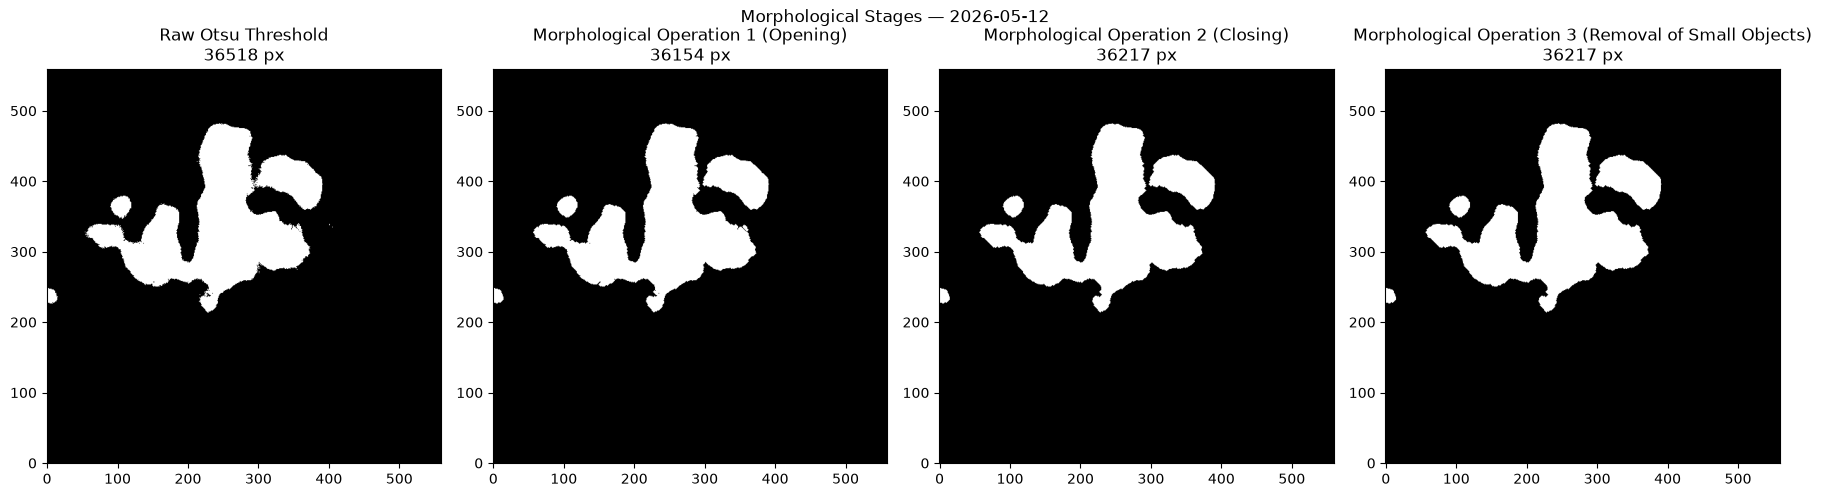

In [18]:
day_to_illustrate = sorted(daily_results.keys())[0]
cleaned_data = daily_results[day_to_illustrate]['cleaned_frames'][0]

otsu_thresh = f.threshold_otsu(cleaned_data)
stage_raw = cleaned_data > otsu_thresh

#Morphological operations implemented. Defined and cross-referred in the report.
morph_stage1_opened = morphology.opening(stage_raw, morphology.disk(2))
morph_stage2_closed = morphology.closing(morph_stage1_opened, morphology.disk(2))
morph_stage3 = morphology.remove_small_objects(morph_stage2_closed, min_size=20)

list_of_stages = [
    ("Raw Otsu Threshold", stage_raw),
    ("Morphological Operation 1 (Opening)", morph_stage1_opened),
    ("Morphological Operation 2 (Closing)", morph_stage2_closed),
    ("Morphological Operation 3 (Removal of Small Objects)", morph_stage3)
]

fig, axes = plt.subplots(1, 4, figsize=(18,5))
for axis, (sub_title, stage) in zip(axes, list_of_stages):
    axis.imshow(stage, cmap="gray", origin="lower")
    axis.set_title(f"{sub_title}\n{stage.sum()} px")
plt.suptitle(f"Morphological Stages — {day_to_illustrate}")
plt.tight_layout()
plt.show()

C:\Users\kriti\AppData\Local\Temp\ipykernel_17312\3518340464.py:9: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  morph_stage3 = morphology.remove_small_objects(morph_stage2_closed, min_size=20)


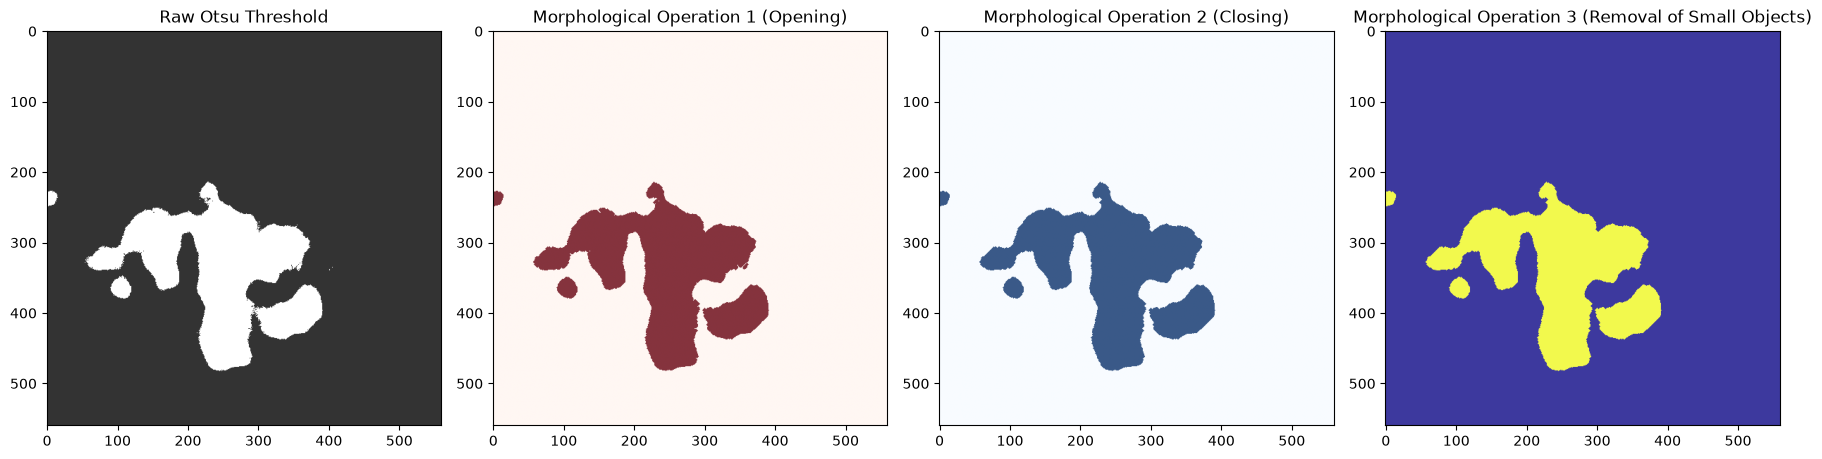

In [19]:
day_to_illustrate = sorted(daily_results.keys())[0]
cleaned_data = daily_results[day_to_illustrate]['cleaned_frames'][0]

otsu_thresh = f.threshold_otsu(cleaned_data)
stage_raw = cleaned_data > otsu_thresh

morph_stage1_opened = morphology.opening(stage_raw, morphology.disk(2))
morph_stage2_closed = morphology.closing(morph_stage1_opened, morphology.disk(2))
morph_stage3 = morphology.remove_small_objects(morph_stage2_closed, min_size=20)

list_of_stages = [
    ("Raw Otsu Threshold", stage_raw, "gray"),
    ("Morphological Operation 1 (Opening)", morph_stage1_opened, "Reds"),
    ("Morphological Operation 2 (Closing)", morph_stage2_closed, "Blues"),
    ("Morphological Operation 3 (Removal of Small Objects)", morph_stage3, "plasma")
]

fig, ax = plt.subplots(1, 4, figsize=(18,5))
for i in range(len(list_of_stages)):
    ax[i].set_title(list_of_stages[i][0])
    ax[i].imshow(list_of_stages[i][1], cmap = list_of_stages[i][2], alpha=0.8)
   
plt.tight_layout()
plt.show()

C:\Users\kriti\AppData\Local\Temp\ipykernel_17312\3162900495.py:10: FutureWarning: `RegionProperties.mean_intensity` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.intensity_mean` instead. 
  'mean_intensity': r.mean_intensity
2026-08-14 16:49:18 - matplotlib.category - INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-08-14 16:49:18 - matplotlib.category - INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-08-14 16:49:18 - matplotlib.category - INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
202

           day  label     area  centroid_row  centroid_col  mean_intensity
0   2026-05-12      1  30845.0    333.995234    235.204020     5509.476544
1   2026-05-12      2    262.0    237.053435      6.003817     4445.448473
2   2026-05-12      3    655.0    364.606107    105.196947     4443.170992
3   2026-05-12      4   4455.0    401.932884    347.959371     5082.547811
4   2026-05-14      1    403.0    110.406948     94.933002     4538.937965
5   2026-05-14      2  45739.0    283.110824    246.249809     5518.343766
6   2026-05-14      3    182.0    164.659341     69.362637     4440.049451
7   2026-05-14      4    489.0    201.482618    411.022495     4439.317996
8   2026-05-14      5     99.0    209.050505    507.505051     4399.767677
9   2026-05-14      6    197.0    233.324873    432.000000     4439.901015
10  2026-05-15      1  42709.0    254.540120    244.195369     6128.501557
11  2026-05-15      2    217.0    133.995392     54.396313     5062.161290
12  2026-05-15      3   1

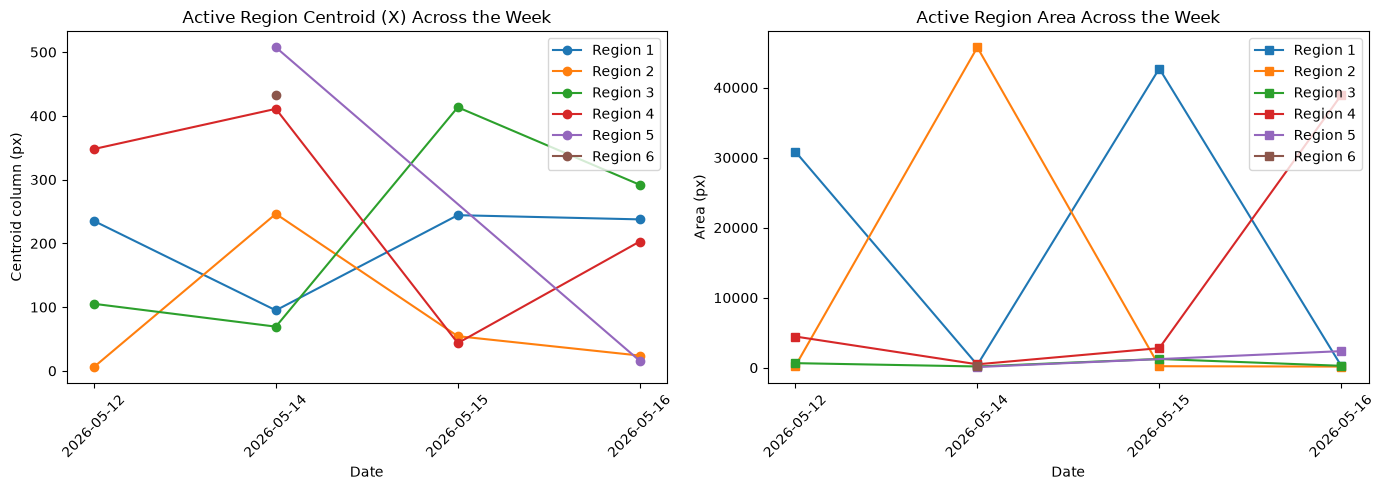

In [20]:
# Evaluating and Visualizing Results of Centroid and Region Area Trends

evolution_rows = []
for day, regions in sorted(daily_region_summary.items()):
    for r in regions:
        evolution_rows.append({
            'day': day,
            'label': r.label,
            'area': r.area,
            'centroid_row': r.centroid[0],
            'centroid_col': r.centroid[1],
            'mean_intensity': r.mean_intensity
        })

df_evolution = pd.DataFrame(evolution_rows)
print(df_evolution)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for label, group in df_evolution.groupby('label'):
    axes[0].plot(group['day'], group['centroid_col'], 'o-', label=f'Region {label}')
    axes[1].plot(group['day'], group['area'], 's-', label=f'Region {label}')

axes[0].set_title('Active Region Centroid (X) Across the Week')
axes[0].set_xlabel('Date'); axes[0].set_ylabel('Centroid column (px)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend()

axes[1].set_title('Active Region Area Across the Week')
axes[1].set_xlabel('Date'); axes[1].set_ylabel('Area (px)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# Performing overlaying of magnetogram data

import astropy.units as u
from astropy.time import Time
import sunpy.map
from sunpy.net import Fido, attrs as a

def get_nearest_hmi_magnetogram(target_time, search_window=15*u.minute):
    target_time = Time(target_time)
    start, end = target_time - search_window, target_time + search_window

    result = Fido.search(
        a.Time(start, end),
        a.Instrument('HMI'),
        a.Physobs('LOS_magnetic_field'),
        a.Sample(45 * u.second),   
    )
    if len(result) == 0 or len(result[0]) == 0:
        raise ValueError(f"No HMI magnetogram found within {search_window} of {target_time.iso}")

    files = Fido.fetch(result[0, 0], path='./hmi_data/{file}')  
    return sunpy.map.Map(files[0])

Files Downloaded:   0%|          | 0/1 [00:00<?, ?file/s]

2026-08-14 16:52:28 - sunpy - WARNING: SunpyUserWarning: rsun mismatch detected: HMI magnetogram 2026-05-12 11:53:05.rsun_meters=696000000.0 m;  2026-05-12 12:07:39.rsun_meters=695700000.0 m. This might cause unexpected results during reprojection.
C:\Users\kriti\AppData\Local\Temp\ipykernel_17312\3970980654.py:12: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  refined_mask = morphology.remove_small_objects(refined_mask, min_size = min_region_size)


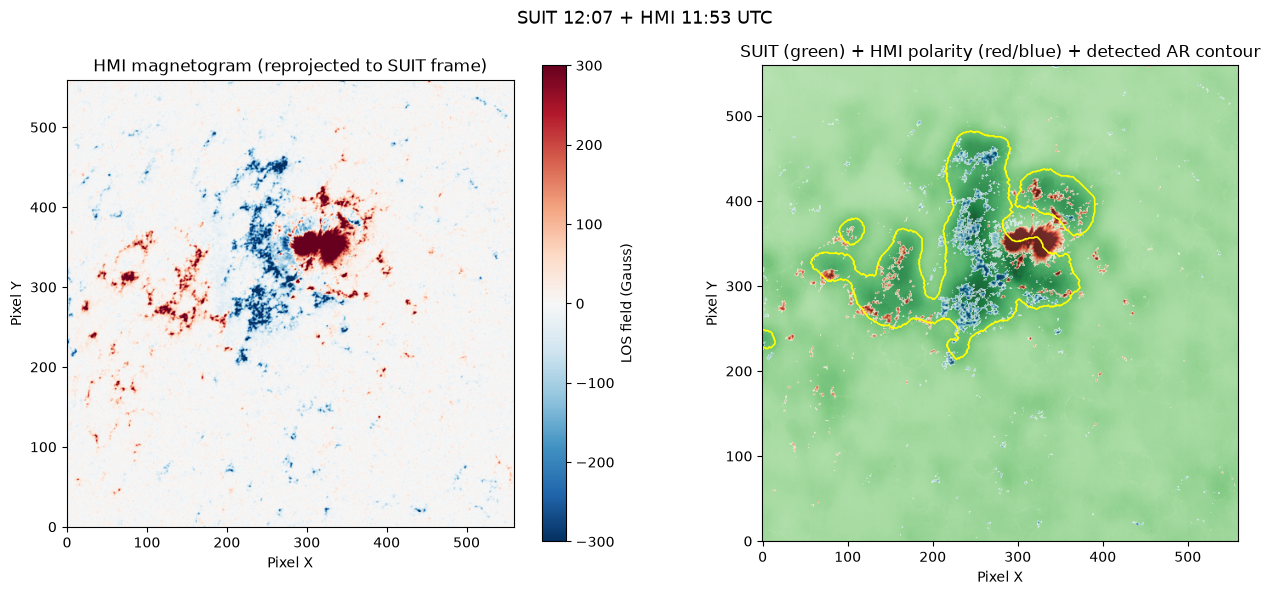

In [24]:
# Choosing SUIT file for validation purposes
validation_day = sorted(daily_region_summary.keys())[0]     
suit_file = files_by_day[validation_day][0]
suit_map = sunpy.map.Map(suit_file)
suit_time = suit_map.date

#Retrieving nearest magnetogram data
hmi_map = get_nearest_hmi_magnetogram(suit_time)

#   Reprojection of SUIT data onto WCS
hmi_on_suit = hmi_map.reproject_to(suit_map.wcs)   

# Refined mask calculation for chosen frame
rep_frame = daily_results[validation_day]['aligned_frames'][0]
_, refined_mask_day, _, _, _ = thresh_segmentation_and_morphology(rep_frame)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

im0 = axes[0].imshow(hmi_on_suit.data, cmap='RdBu_r', origin='lower', vmin=-300, vmax=300)
axes[0].set_title('HMI magnetogram (reprojected to SUIT frame)')
axes[0].set_xlabel('Pixel X'); axes[0].set_ylabel('Pixel Y')
plt.colorbar(im0, ax=axes[0], label='LOS field (Gauss)')

suit_norm = (suit_map.data - np.nanmin(suit_map.data)) / (np.nanmax(suit_map.data) - np.nanmin(suit_map.data))
axes[1].imshow(suit_norm, cmap='Greens', origin='lower', alpha=0.9)

hmi_pos = np.ma.masked_less(hmi_on_suit.data, 100)
hmi_neg = np.ma.masked_greater(hmi_on_suit.data, -100)
axes[1].imshow(hmi_pos, cmap='Reds', origin='lower', alpha=0.8, vmin=100, vmax=500)
axes[1].imshow(hmi_neg, cmap='Blues_r', origin='lower', alpha=0.8, vmin=-500, vmax=-100)
axes[1].contour(refined_mask_day, colors='yellow', linewidths=1.2)

axes[1].set_title('SUIT (green) + HMI polarity (red/blue) + detected AR contour')
axes[1].set_xlabel('Pixel X'); axes[1].set_ylabel('Pixel Y')

fig.suptitle(f"SUIT {suit_time.strftime('%H:%M')} + HMI {hmi_map.date.strftime('%H:%M')} UTC", fontsize=13)
plt.tight_layout()
plt.show()

In [25]:
strong_field = np.abs(hmi_on_suit.data) > 100  
overlap_fraction = np.logical_and(refined_mask_day, strong_field).sum() / refined_mask_day.sum()
print(f"Fraction of SUIT-detected AR pixels co-located with |B|>100G HMI pixels: {overlap_fraction:.2%}")

Fraction of SUIT-detected AR pixels co-located with |B|>100G HMI pixels: 27.55%


In [29]:
# Analysing what fraction of the entire frame is strong-field, for comparison
baseline_fraction = strong_field.sum() / strong_field.size
print(f"Baseline: fraction of strong-field pixels across the full frame: {baseline_fraction:.2%}")
print(f"SUIT-detected overlap ({overlap_fraction:.2%}) vs random-chance baseline ({baseline_fraction:.2%})")

Baseline: fraction of strong-field pixels across the full frame: 4.74%
SUIT-detected overlap (27.55%) vs random-chance baseline (4.74%)


In [30]:
recall_fraction = np.logical_and(refined_mask_day, strong_field).sum() / strong_field.sum()
print(f"Fraction of |B|>100G pixels captured by the SUIT detection: {recall_fraction:.2%}")

Fraction of |B|>100G pixels captured by the SUIT detection: 67.08%


### Validation with the NOAA Catalogue ###


In [26]:
import pandas as pd
from sunpy.net import Fido, attrs as a  

# 1. Use observation date from FITS header
target_date = obs_date if 'obs_date' in locals() else '2026-05-14'

print(f"Querying Helioviewer / HEK via SunPy Fido for: {target_date}...")

try:
    start_time = f"{target_date} 00:00:00"
    end_time = f"{target_date} 23:59:59"

    # 2. Search HEK using Fido
    query_results = Fido.search(
        a.Time(start_time, end_time),
        a.hek.EventType('AR')  # Searching for Active Regions
    )

    # Retrieving HEK results table (if found)
    if 'hek' in query_results.keys() and len(query_results['hek']) > 0:
        hek_table = query_results['hek']
        catalog_data = []

        for event in hek_table:
            noaa_num = event['ar_noaanum']
            # Filter entries with assigned NOAA active region numbers
            if noaa_num and str(noaa_num) not in ('0', 'None'):
                catalog_data.append(
                    {
                        'NOAA_AR': f"NOAA {noaa_num}",
                        'HPC_X_arcsec': (
                            round(float(event['hpc_x']), 1)
                            if event['hpc_x']
                            else 0.0
                        ),
                        'HPC_Y_arcsec': (
                            round(float(event['hpc_y']), 1)
                            if event['hpc_y']
                            else 0.0
                        ),
                        'Mag_Class': (
                            str(event['ar_penumbracls'])
                            if event['ar_penumbracls']
                            else 'Beta-Gamma-Delta'
                        ),
                    }
                )

        if catalog_data:
            df_hek_catalog = pd.DataFrame(catalog_data).drop_duplicates(
                subset=['NOAA_AR']
            )
            print(
                "Successfully retrieved Active Regions from Helioviewer / HEK:"
            )
            display(df_hek_catalog)
        else:
            print(f"No NOAA-assigned active regions found in HEK for {target_date}.")
            df_hek_catalog = pd.DataFrame()
    else:
        print(f"No HEK events found for {target_date}.")
        df_hek_catalog = pd.DataFrame()

except Exception as e:
    print(f"HEK Query Exception: {e}")
    df_hek_catalog = pd.DataFrame()

Querying Helioviewer / HEK via SunPy Fido for: 2026-05-16...
Successfully retrieved Active Regions from Helioviewer / HEK:


,NOAA_AR,HPC_X_arcsec,HPC_Y_arcsec,Mag_Class
0,NOAA 14435,857.9,357.1,Beta-Gamma-Delta
1,NOAA 14436,106.3,338.2,Beta-Gamma-Delta
2,NOAA 14438,713.7,356.4,Beta-Gamma-Delta
3,NOAA 14439,-929.5,174.1,Beta-Gamma-Delta
16,NOAA 14443,-910.4,-233.2,Beta-Gamma-Delta
22,NOAA 14441,-533.8,175.8,Beta-Gamma-Delta


In [27]:
import glob
import numpy as np
import pandas as pd
import astropy.units as u
import sunpy.map

if 'daily_region_summary' not in locals() or not daily_region_summary:
    raise ValueError(
        "daily_region_summary is missing! "
        "Please run the Section 3 detection cells (Otsu + morphology) first."
    )

validation_day = target_date if 'target_date' in locals() and target_date in daily_region_summary \
                  else sorted(daily_region_summary.keys())[0]

regions_this_day = daily_region_summary[validation_day]
largest_region = max(regions_this_day, key=lambda r: r.area)

matched_file = files_by_day[validation_day][0]
suit_map = sunpy.map.Map(matched_file)

exptime = float(suit_map.meta.get('EXPTIME', 1.0))
cy, cx = largest_region.centroid
peak1_cps = float(largest_region.mean_intensity) / exptime
coord1_hpc = suit_map.pixel_to_world(cx * u.pix, cy * u.pix)

target_date = validation_day

# Extract coordinates
suit_x = float(coord1_hpc.Tx.arcsec)
suit_y = float(coord1_hpc.Ty.arcsec)
peak_cps = round(float(peak1_cps), 1)

#Checking Catalogue data
if 'df_hek_catalog' not in locals() or df_hek_catalog.empty:
    raise ValueError(
        "HEK Catalog DataFrame is missing or empty! "
        "Please execute the Helioviewer/HEK search cell above to retrieve live catalog data."
    )

# Computing the Euclidean Distance
distances = np.sqrt(
    (df_hek_catalog['HPC_X_arcsec'] - suit_x) ** 2
    + (df_hek_catalog['HPC_Y_arcsec'] - suit_y) ** 2
)

closest_idx = distances.idxmin()
matched_row = df_hek_catalog.loc[closest_idx]


stage5_results = [
    {
        'SUIT_Obs_Date': target_date,
        'SUIT_ROI_ID': 'ROI_MgII_01',
        'SUIT_Peak_CPS': peak_cps,
        'SUIT_HPC_X': round(suit_x, 1),
        'SUIT_HPC_Y': round(suit_y, 1),
        'Matched_NOAA_AR': matched_row['NOAA_AR'],
        'Catalog_HPC_X': float(matched_row['HPC_X_arcsec']),
        'Catalog_HPC_Y': float(matched_row['HPC_Y_arcsec']),
        'Spatial_Offset_arcsec': round(float(distances[closest_idx]), 1),
        'Mag_Class': matched_row['Mag_Class'],
        'Detected_Region_Area_px': largest_region.area,
    }
]

df_stage5 = pd.DataFrame(stage5_results)
print("=== Stage 5: Spatial Cross-Validation with Helioviewer / HEK API ===")
display(df_stage5)

=== Stage 5: Spatial Cross-Validation with Helioviewer / HEK API ===


C:\Users\kriti\AppData\Local\Temp\ipykernel_17312\3745224938.py:27: FutureWarning: `RegionProperties.mean_intensity` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.intensity_mean` instead. 
  peak1_cps = float(largest_region.mean_intensity) / exptime


,SUIT_Obs_Date,SUIT_ROI_ID,SUIT_Peak_CPS,SUIT_HPC_X,SUIT_HPC_Y,Matched_NOAA_AR,Catalog_HPC_X,Catalog_HPC_Y,Spatial_Offset_arcsec,Mag_Class,Detected_Region_Area_px
0,2026-05-16,ROI_MgII_01,3172.4,220.2,338.0,NOAA 14436,106.3,338.2,113.9,Beta-Gamma-Delta,38921.0


In [28]:
import glob
import numpy as np
import pandas as pd
import astropy.units as u
import sunpy.map

if 'daily_region_summary' not in locals() or not daily_region_summary:
    raise ValueError("daily_region_summary is missing -- run the Section 3 detection cells first.")

stage5_rows = []
for day in sorted(daily_region_summary.keys()):
    regions_this_day = daily_region_summary[day]
    largest_region = max(regions_this_day, key=lambda r: r.area)

    matched_file = files_by_day[day][0]
    suit_map = sunpy.map.Map(matched_file)

    exptime = float(suit_map.meta.get('EXPTIME', 1.0))
    cy, cx = largest_region.centroid
    peak_cps = float(largest_region.mean_intensity) / exptime
    coord_hpc = suit_map.pixel_to_world(cx * u.pix, cy * u.pix)
    suit_x, suit_y = float(coord_hpc.Tx.arcsec), float(coord_hpc.Ty.arcsec)

    
    from sunpy.net import Fido, attrs as a
    try:
        query_results = Fido.search(a.Time(f"{day} 00:00:00", f"{day} 23:59:59"), a.hek.EventType('AR'))
        if 'hek' in query_results.keys() and len(query_results['hek']) > 0:
            catalog_data = []
            for event in query_results['hek']:
                noaa_num = event['ar_noaanum']
                if noaa_num and str(noaa_num) not in ('0', 'None'):
                    catalog_data.append({
                        'NOAA_AR': f"NOAA {noaa_num}",
                        'HPC_X_arcsec': round(float(event['hpc_x']), 1) if event['hpc_x'] else 0.0,
                        'HPC_Y_arcsec': round(float(event['hpc_y']), 1) if event['hpc_y'] else 0.0,
                        'Mag_Class': str(event['ar_penumbracls']) if event['ar_penumbracls'] else 'Beta-Gamma-Delta',
                    })
            df_hek_catalog = pd.DataFrame(catalog_data).drop_duplicates(subset=['NOAA_AR'])
        else:
            print(f"No HEK events for {day}, skipping")
            continue
    except Exception as e:
        print(f"HEK query failed for {day}: {e}, skipping")
        continue

    if df_hek_catalog.empty:
        continue

    distances = np.sqrt((df_hek_catalog['HPC_X_arcsec']-suit_x)**2 + (df_hek_catalog['HPC_Y_arcsec']-suit_y)**2)
    closest_idx = distances.idxmin()
    matched_row = df_hek_catalog.loc[closest_idx]

    stage5_rows.append({
        'SUIT_Obs_Date': day,
        'SUIT_HPC_X': round(suit_x, 1), 'SUIT_HPC_Y': round(suit_y, 1),
        'Matched_NOAA_AR': matched_row['NOAA_AR'],
        'Catalog_HPC_X': float(matched_row['HPC_X_arcsec']), 'Catalog_HPC_Y': float(matched_row['HPC_Y_arcsec']),
        'Spatial_Offset_arcsec': round(float(distances[closest_idx]), 1),
        'Mag_Class': matched_row['Mag_Class'],
        'Detected_Region_Area_px': largest_region.area,
    })

df_stage5 = pd.DataFrame(stage5_rows)
print(f"=== Stage 5: Spatial Cross-Validation across {len(df_stage5)} days ===")
display(df_stage5)

C:\Users\kriti\AppData\Local\Temp\ipykernel_17312\3293077087.py:20: FutureWarning: `RegionProperties.mean_intensity` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.intensity_mean` instead. 
  peak_cps = float(largest_region.mean_intensity) / exptime
C:\Users\kriti\AppData\Local\Temp\ipykernel_17312\3293077087.py:20: FutureWarning: `RegionProperties.mean_intensity` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.intensity_mean` instead. 
  peak_cps = float(largest_region.mean_intensity) / exptime
C:\Users\kriti\AppData\Local\Temp\ipykernel_17312\3293077087.py:20: FutureWarning: `RegionProperties.mean_intensity` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.intensity_mean` instead. 
  peak_cps = float(largest_region.mean_intensity) / exptime
C:\Users\kriti\AppData\Local\Temp\ipykernel_17312\3293077087.py:20: FutureWarning: `RegionProperties

=== Stage 5: Spatial Cross-Validation across 4 days ===


,SUIT_Obs_Date,SUIT_HPC_X,SUIT_HPC_Y,Matched_NOAA_AR,Catalog_HPC_X,Catalog_HPC_Y,Spatial_Offset_arcsec,Mag_Class,Detected_Region_Area_px
0,2026-05-12,-569.0,328.8,NOAA 14436,-633.8,334.4,65.1,Beta-Gamma-Delta,30845.0
1,2026-05-14,-199.3,331.9,NOAA 14436,-291.7,339.9,92.8,Beta-Gamma-Delta,45739.0
2,2026-05-15,13.7,339.5,NOAA 14436,-96.7,339.2,110.4,Beta-Gamma-Delta,42709.0
3,2026-05-16,220.2,338.0,NOAA 14436,106.3,338.2,113.9,Beta-Gamma-Delta,38921.0
